# Solving constrained mean-variance portfolios

A fully invested portfolio has expected return and variance given by:

$$
\mu_p=w^{\mathsf T}\mu,
\qquad
\sigma_p^2=w^{\mathsf T}\Sigma w,
\qquad
\mathbf 1^{\mathsf T}w=1.
$$

Here, $w$ is the vector of portfolio weights, $\mu$ is the vector of expected asset returns, $\mu_p$ is the portfolio's expected return, $\Sigma$ is the asset-return covariance matrix, $\sigma_p^2$ is portfolio variance, $\mathbf 1$ is a vector of ones, and $\mathsf T$ denotes transpose.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf
from IPython.display import Image

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.data.denoise import corr_to_cov, cov_to_corr, denoise_cov
from RiskLabAI.data.synthetic_data import form_true_matrix, simulates_cov_mu
from RiskLabAI.optimization import get_optimal_portfolio_weights

FIGURES = ROOT / "outputs" / "figures" / "23_portfolio_geometry"
TABLES = ROOT / "outputs" / "tables" / "23_portfolio_geometry"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = latex.replace("nan", "Not available").replace("NaN", "Not available").replace("inf", "No finite value")
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

def global_minimum_variance(covariance):
    inverse_ones = np.linalg.solve(covariance, np.ones(covariance.shape[0]))
    return inverse_ones / inverse_ones.sum()

def mean_return_weighted(covariance, expected_return):
    direction = np.linalg.solve(covariance, np.asarray(expected_return, dtype=float))
    return direction / direction.sum()

def inverse_variance(covariance):
    weights = 1.0 / np.diag(covariance)
    return weights / weights.sum()

def long_only_minimum_variance(covariance):
    asset_count = covariance.shape[0]
    objective = lambda weights: float(weights @ covariance @ weights)
    gradient = lambda weights: 2.0 * covariance @ weights
    result = minimize(objective, np.repeat(1.0 / asset_count, asset_count), jac=gradient, method="SLSQP", bounds=[(0.0, 1.0)] * asset_count, constraints=[{"type": "eq", "fun": lambda weights: weights.sum() - 1.0, "jac": lambda weights: np.ones(asset_count)}], options={"ftol": 1e-12, "maxiter": 2000})
    assert result.success
    return result.x

def norm_limited_minimum_variance(covariance, squared_norm_limit):
    asset_count = covariance.shape[0]
    objective = lambda weights: float(weights @ covariance @ weights)
    gradient = lambda weights: 2.0 * covariance @ weights
    constraints = [
        {"type": "eq", "fun": lambda weights: weights.sum() - 1.0, "jac": lambda weights: np.ones(asset_count)},
        {"type": "ineq", "fun": lambda weights: squared_norm_limit - float(weights @ weights), "jac": lambda weights: -2.0 * weights},
    ]
    result = minimize(objective, np.repeat(1.0 / asset_count, asset_count), jac=gradient, method="SLSQP", constraints=constraints, options={"ftol": 1e-12, "maxiter": 3000})
    assert result.success
    return result.x

def target_return_portfolio(covariance, expected_return, target):
    asset_count = covariance.shape[0]
    constraint_matrix = np.column_stack([np.ones(asset_count), expected_return])
    inverse_constraint = np.linalg.solve(covariance, constraint_matrix)
    middle = constraint_matrix.T @ inverse_constraint
    return inverse_constraint @ np.linalg.solve(middle, np.array([1.0, target]))

def portfolio_record(name, weights, expected_return, covariance):
    weights = np.asarray(weights, dtype=float).reshape(-1)
    return {
        "Portfolio": name,
        "Expected annual return": float(weights @ expected_return),
        "Annual volatility": float(np.sqrt(weights @ covariance @ weights)),
        "Largest long weight": float(weights.max()),
        "Smallest weight": float(weights.min()),
        "Gross exposure": float(np.abs(weights).sum()),
        "Weight concentration": float(weights @ weights),
        "Effective holdings": float(1.0 / (weights @ weights)),
    }

data_provenance = pd.DataFrame({
    "Field": ["Archive", "Provider", "Return type", "Analysis start", "Analysis end", "Complete dates", "Industry portfolios", "File SHA256"],
    "Value": ["49_Industry_Portfolios_daily_CSV.zip", "Kenneth R. French Data Library", "Daily value-weighted return", str(industry_returns.index.min().date()), str(industry_returns.index.max().date()), len(industry_returns), industry_returns.shape[1], data_hash],
})

geometry_assets = list(industry_returns.columns[:12])
geometry_sample = industry_returns.loc[:"2022-12-31", geometry_assets]
geometry_mean = geometry_sample.mean().to_numpy() * 252.0
geometry_covariance = geometry_sample.cov().to_numpy() * 252.0
geometry_count = len(geometry_assets)
geometry_names = np.array(geometry_assets)

save_table(data_provenance, "geometry_data_provenance", "Public data used for the Chapter 20 portfolio study.", "tab:chapter20-geometry-data")
display(data_provenance)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


,Field,Value
0,Archive,49_Industry_Portfolios_daily_CSV.zip
1,Provider,Kenneth R. French Data Library
2,Return type,Daily value-weighted return
3,Analysis start,2019-01-02
4,Analysis end,2025-12-31
5,Complete dates,1760
6,Industry portfolios,49
7,File SHA256,8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71...


## The Unrestricted Frontier

The fully invested portfolio with the smallest variance and the portfolio with a chosen expected return are:

$$
w_{\mathrm{GMV}}
=\frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mathbf 1},
\qquad
w(r)
=\Sigma^{-1}C\left(C^{\mathsf T}\Sigma^{-1}C\right)^{-1}
\begin{bmatrix}1\\r\end{bmatrix},
\qquad
C=\begin{bmatrix}\mathbf 1&\mu\end{bmatrix}.
$$

Here, $w_{\mathrm{GMV}}$ is the global minimum-variance weight vector, $w(r)$ is the minimum-variance vector whose expected return is $r$, $\Sigma^{-1}$ is the inverse covariance matrix, $C$ collects the budget and return directions, and the two entries in the right-hand vector impose total weight one and expected return $r$.

,Check,Value
0,GMV weights sum to one,1
1,RiskLabAI GMV agrees,0
2,Mean-return weights sum to one,1
3,RiskLabAI mean-return weights agree,0
4,GMV first-order spread,0
5,Largest frontier budget error,0
6,Largest frontier return error,0


,Portfolio,Expected annual return,Annual volatility,Largest long weight,Smallest weight,Gross exposure,Weight concentration,Effective holdings
0,Equal weight,0.132919,0.212594,0.083333,0.083333,1,0.083333,12
1,Inverse variance,0.136507,0.197264,0.159722,0.033265,1,0.099156,10.085072
2,Unrestricted GMV,0.125365,0.177758,0.717866,-0.183448,1.649588,0.650151,1.538103
3,Mean-return weighted,0.231128,0.241362,0.569152,-0.219865,2.108698,0.630908,1.585018


,Target annual return,Achieved annual return,Annual volatility,Gross exposure
0,0.078370,0.078370,0.191993,2.687984
20,0.091140,0.091140,0.185444,2.395406
40,0.103911,0.103911,0.180817,2.102827
60,0.116681,0.116681,0.178263,1.810249
80,0.129452,0.129452,0.177870,1.615452
100,0.142222,0.142222,0.179653,1.525828
120,0.154992,0.154992,0.183548,1.440070


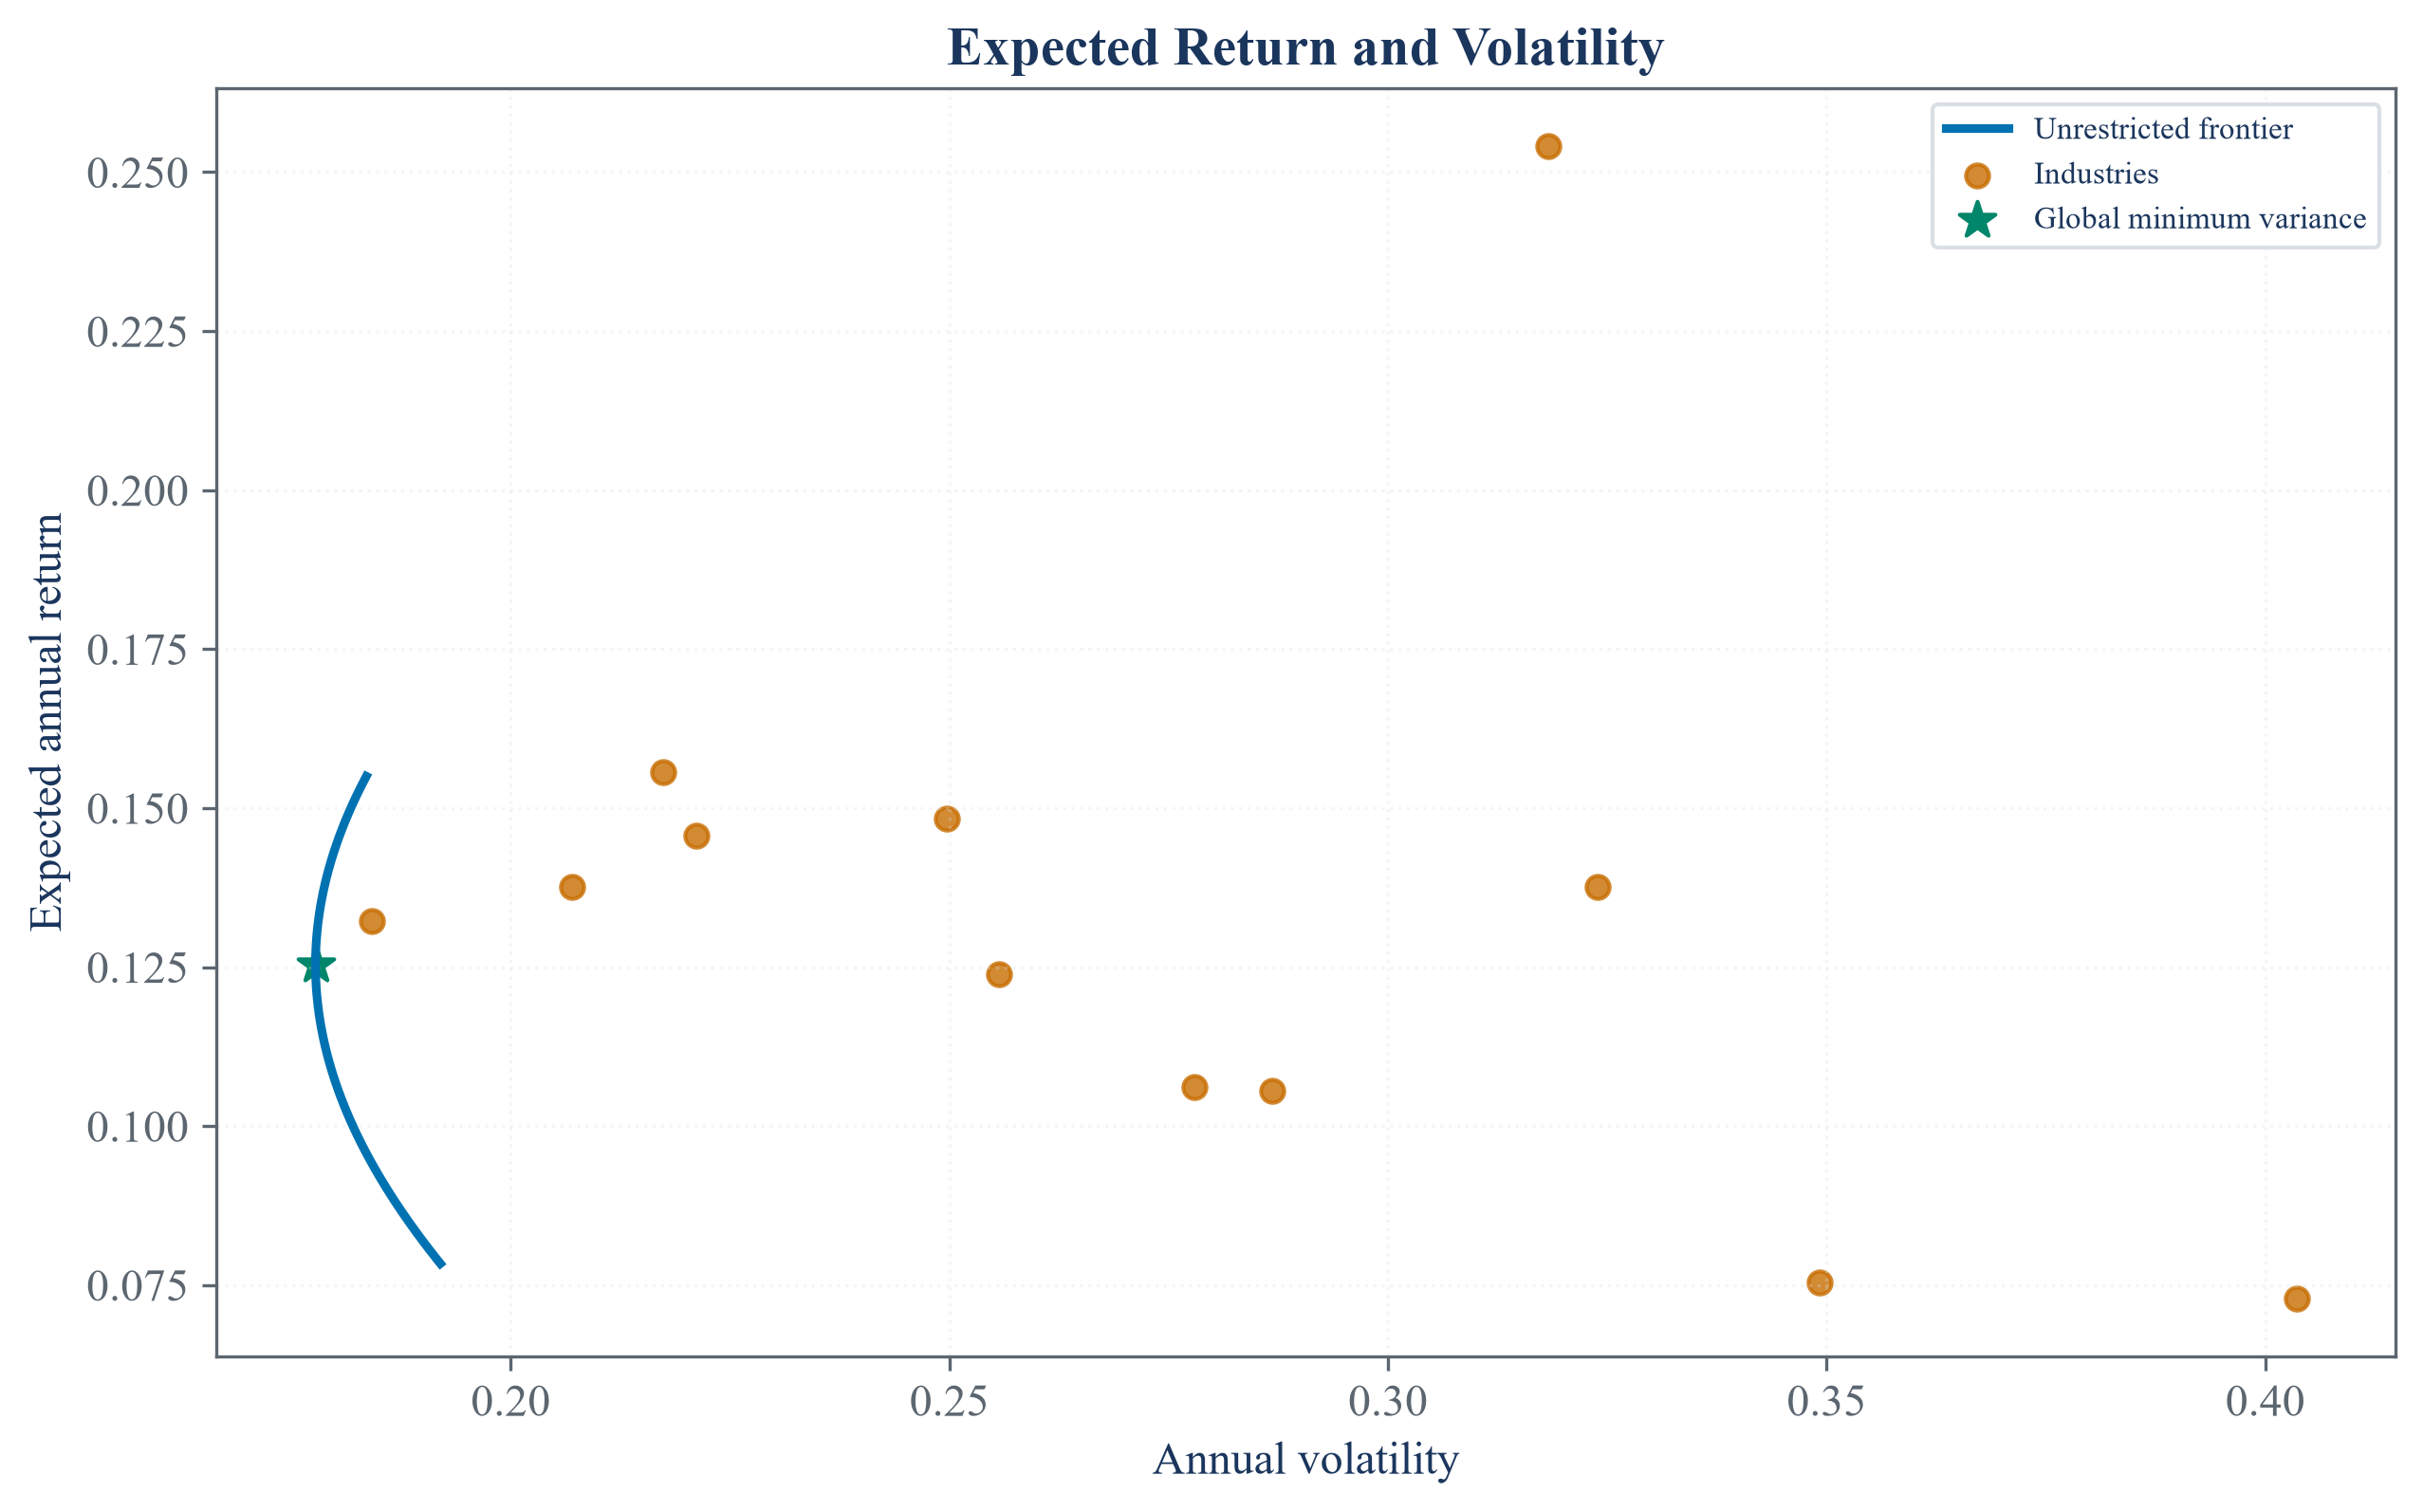

In [2]:
gmv_weights = global_minimum_variance(geometry_covariance)
library_gmv_weights = get_optimal_portfolio_weights(geometry_covariance).reshape(-1)
mean_weights = mean_return_weighted(geometry_covariance, geometry_mean)
library_mean_weights = get_optimal_portfolio_weights(geometry_covariance, geometry_mean.reshape(-1, 1)).reshape(-1)
target_grid = np.linspace(np.quantile(geometry_mean, 0.10), np.quantile(geometry_mean, 0.90), 121)
frontier_weights = np.vstack([target_return_portfolio(geometry_covariance, geometry_mean, target) for target in target_grid])
frontier_returns = frontier_weights @ geometry_mean
frontier_volatility = np.sqrt(np.einsum("ij,jk,ik->i", frontier_weights, geometry_covariance, frontier_weights))
asset_volatility = np.sqrt(np.diag(geometry_covariance))

analytical_checks = pd.DataFrame({
    "Check": ["GMV weights sum to one", "RiskLabAI GMV agrees", "Mean-return weights sum to one", "RiskLabAI mean-return weights agree", "GMV first-order spread", "Largest frontier budget error", "Largest frontier return error"],
    "Value": [gmv_weights.sum(), np.max(np.abs(gmv_weights - library_gmv_weights)), mean_weights.sum(), np.max(np.abs(mean_weights - library_mean_weights)), np.ptp(geometry_covariance @ gmv_weights), np.max(np.abs(frontier_weights.sum(axis=1) - 1.0)), np.max(np.abs(frontier_returns - target_grid))],
})
geometry_summary = pd.DataFrame([
    portfolio_record("Equal weight", np.repeat(1.0 / geometry_count, geometry_count), geometry_mean, geometry_covariance),
    portfolio_record("Inverse variance", inverse_variance(geometry_covariance), geometry_mean, geometry_covariance),
    portfolio_record("Unrestricted GMV", gmv_weights, geometry_mean, geometry_covariance),
    portfolio_record("Mean-return weighted", mean_weights, geometry_mean, geometry_covariance),
])
frontier_audit = pd.DataFrame({"Target annual return": target_grid, "Achieved annual return": frontier_returns, "Annual volatility": frontier_volatility, "Gross exposure": np.abs(frontier_weights).sum(axis=1)})
save_table(analytical_checks, "geometry_analytical_checks", "Direct checks of the closed-form portfolio calculations.", "tab:chapter20-geometry-checks")
save_table(geometry_summary, "geometry_portfolio_summary", "Public-sample portfolios before weight constraints.", "tab:chapter20-geometry-summary")
save_table(frontier_audit.iloc[::20].reset_index(drop=True), "frontier_audit", "Selected points from the unrestricted mean-variance frontier.", "tab:chapter20-frontier-audit")
display(analytical_checks)
display(geometry_summary.round(6))
display(frontier_audit.iloc[::20].round(6))

figure, axis = plt.subplots(figsize=(8.4, 5.2), constrained_layout=True)
axis.plot(frontier_volatility, frontier_returns, color=palette["cyan"], linewidth=2.2, label="Unrestricted frontier")
axis.scatter(asset_volatility, geometry_mean, color=palette["amber"], s=34, alpha=0.8, label="Industries")
axis.scatter(np.sqrt(gmv_weights @ geometry_covariance @ gmv_weights), gmv_weights @ geometry_mean, color=palette["green"], s=90, marker="*", label="Global minimum variance")
axis.set_title("Expected Return and Volatility")
axis.set_xlabel("Annual volatility")
axis.set_ylabel("Expected annual return")
axis.grid(alpha=0.28)
axis.legend(fontsize=8)
save_figure(figure, "mean_variance_frontier")

## Comparing two portfolio constraint sets

A long-only minimum-variance portfolio and a norm-limited portfolio solve:

$$
\min_w\;w^{\mathsf T}\Sigma w
\quad\text{subject to}\quad
\mathbf 1^{\mathsf T}w=1,
\qquad
w_i\geq0,
\qquad
\lVert w\rVert_2^2\leq c.
$$

Here, $w_i$ is the weight of asset $i$, $\lVert w\rVert_2^2=\sum_i w_i^2$ measures weight concentration, and $c$ is the largest allowed squared norm. The long-only choice uses the first two constraints, while the norm-limited choice uses the budget and norm constraints and may retain negative weights.

,Portfolio,Expected annual return,Annual volatility,Largest long weight,Smallest weight,Gross exposure,Weight concentration,Effective holdings
0,Equal weight,0.132919,0.212594,0.083333,0.083333,1,0.083333,12
1,Unrestricted GMV,0.125365,0.177758,0.717866,-0.183448,1.649588,0.650151,1.538103
2,Long-only GMV,0.130830,0.180322,0.687515,0,1,0.498101,2.007625
3,Norm-limited GMV,0.138035,0.186786,0.254732,-0.042206,1.084412,0.150000,6.666667


,Portfolio,Expected annual return,Annual volatility,Largest long weight,Smallest weight,Gross exposure,Weight concentration,Effective holdings,Squared norm limit,Constraint gap
0,Norm limit 0.083,0.132919,0.212594,0.083333,0.083333,1,0.083333,12,0.083333,0
1,Norm limit 0.100,0.138333,0.196053,0.151832,0.026146,1,0.100000,10,0.100000,0
2,Norm limit 0.150,0.138035,0.186786,0.254732,-0.042206,1.084412,0.150000,6.666667,0.150000,0
3,Norm limit 0.250,0.134057,0.181425,0.403151,-0.095116,1.190233,0.250000,4,0.250000,0
4,Norm limit 0.500,0.127867,0.178067,0.626247,-0.123345,1.483134,0.500000,2,0.500000,0
5,Norm limit 1,0.125365,0.177758,0.717868,-0.183444,1.649566,0.650151,1.538103,1,0.349849


,Check,Value
0,Long-only budget error,0
1,Smallest long-only weight,0
2,Long-only objective improvement over equal weight,0.01268
3,Norm-limited budget error,0
4,Chosen squared norm,0.15000
5,Chosen norm limit,0.15000
6,Norm constraint gap,0


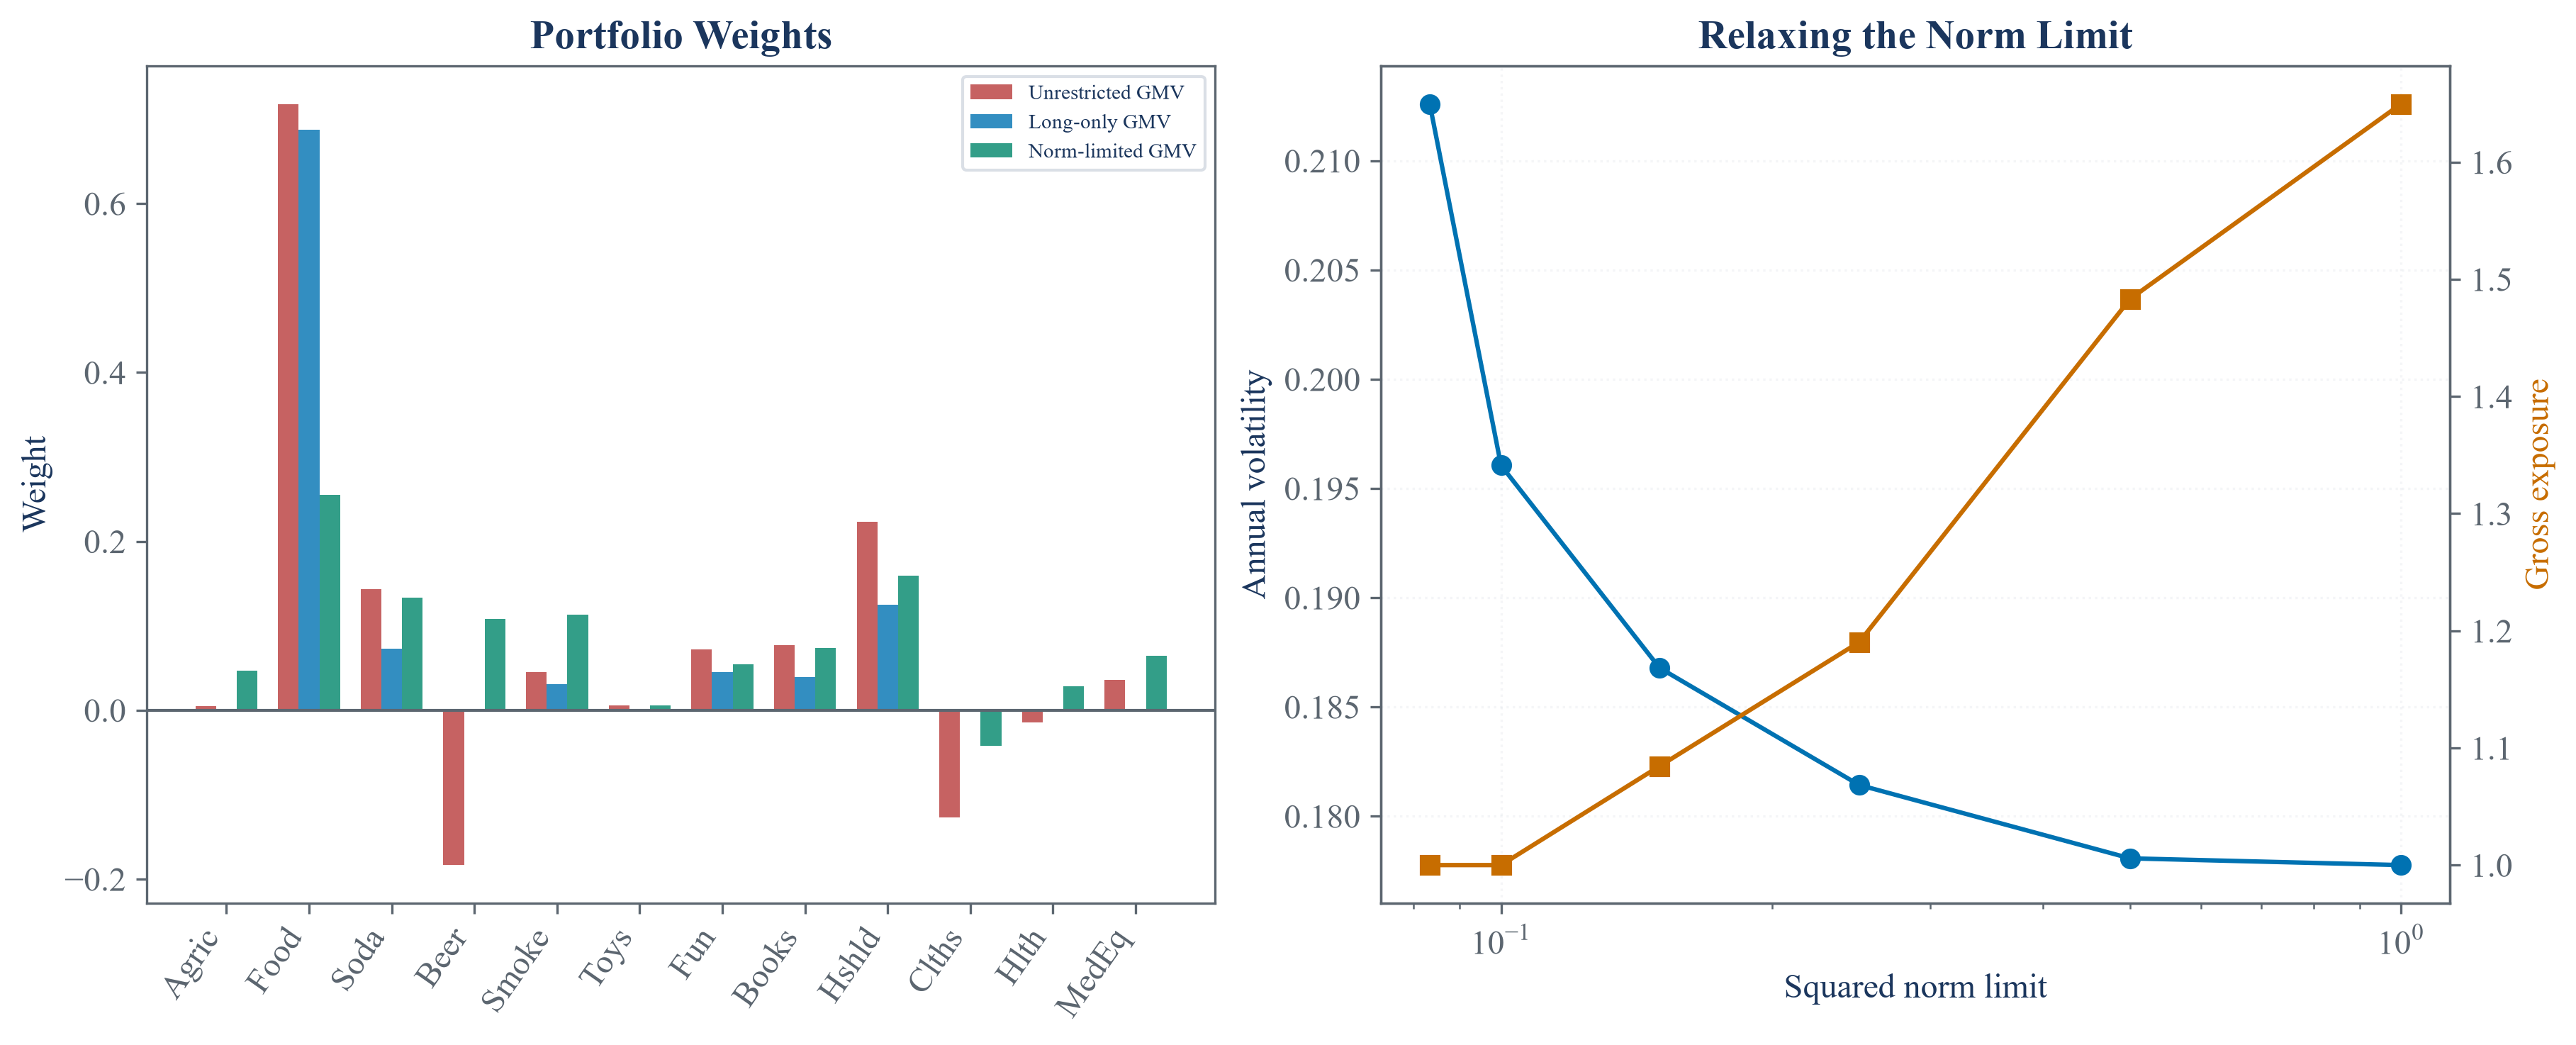

In [3]:
long_only_weights = long_only_minimum_variance(geometry_covariance)
norm_limits = np.array([1.0 / geometry_count, 0.10, 0.15, 0.25, 0.50, 1.00])
norm_rows = []
norm_weight_map = {}
for limit in norm_limits:
    weights = norm_limited_minimum_variance(geometry_covariance, limit)
    norm_weight_map[limit] = weights
    record = portfolio_record(f"Norm limit {limit:.3f}", weights, geometry_mean, geometry_covariance)
    record["Squared norm limit"] = limit
    record["Constraint gap"] = limit - weights @ weights
    norm_rows.append(record)
norm_path = pd.DataFrame(norm_rows)
chosen_norm_limit = 0.15
chosen_norm_weights = norm_weight_map[chosen_norm_limit]
constrained_summary = pd.DataFrame([
    portfolio_record("Equal weight", np.repeat(1.0 / geometry_count, geometry_count), geometry_mean, geometry_covariance),
    portfolio_record("Unrestricted GMV", gmv_weights, geometry_mean, geometry_covariance),
    portfolio_record("Long-only GMV", long_only_weights, geometry_mean, geometry_covariance),
    portfolio_record("Norm-limited GMV", chosen_norm_weights, geometry_mean, geometry_covariance),
])
constrained_checks = pd.DataFrame({
    "Check": ["Long-only budget error", "Smallest long-only weight", "Long-only objective improvement over equal weight", "Norm-limited budget error", "Chosen squared norm", "Chosen norm limit", "Norm constraint gap"],
    "Value": [abs(long_only_weights.sum() - 1.0), long_only_weights.min(), np.repeat(1.0 / geometry_count, geometry_count) @ geometry_covariance @ np.repeat(1.0 / geometry_count, geometry_count) - long_only_weights @ geometry_covariance @ long_only_weights, abs(chosen_norm_weights.sum() - 1.0), chosen_norm_weights @ chosen_norm_weights, chosen_norm_limit, chosen_norm_limit - chosen_norm_weights @ chosen_norm_weights],
})
save_table(constrained_summary, "constrained_portfolio_summary", "Public-sample portfolios with long-only and norm constraints.", "tab:chapter20-constrained-summary")
save_table(norm_path, "norm_limit_path", "Portfolio changes as the squared weight-norm limit is relaxed.", "tab:chapter20-norm-path")
save_table(constrained_checks, "constrained_checks", "Constraint and objective checks for the public quadratic programs.", "tab:chapter20-constrained-checks")
display(constrained_summary.round(6))
display(norm_path.round(6))
display(constrained_checks.round(10))

weight_frame = pd.DataFrame({"Industry": geometry_names, "Unrestricted GMV": gmv_weights, "Long-only GMV": long_only_weights, "Norm-limited GMV": chosen_norm_weights}).melt("Industry", var_name="Portfolio", value_name="Weight")
figure, axes = plt.subplots(1, 2, figsize=(12.0, 4.8), constrained_layout=True)
positions = np.arange(geometry_count)
width = 0.25
for offset, (name, color) in enumerate([("Unrestricted GMV", palette["rose"]), ("Long-only GMV", palette["cyan"]), ("Norm-limited GMV", palette["green"])]):
    values = weight_frame.loc[weight_frame["Portfolio"] == name, "Weight"].to_numpy()
    axes[0].bar(positions + (offset - 1) * width, values, width=width, color=color, alpha=0.80, label=name)
axes[0].axhline(0.0, color=palette["muted"], linewidth=1.0)
axes[0].set_xticks(positions, geometry_names, rotation=55, ha="right")
axes[0].set_title("Portfolio Weights")
axes[0].set_ylabel("Weight")
axes[0].legend(fontsize=7)
axes[1].plot(norm_path["Squared norm limit"], norm_path["Annual volatility"], marker="o", color=palette["cyan"], label="Annual volatility")
second_axis = axes[1].twinx()
second_axis.plot(norm_path["Squared norm limit"], norm_path["Gross exposure"], marker="s", color=palette["amber"], label="Gross exposure")
axes[1].set_xscale("log")
axes[1].set_title("Relaxing the Norm Limit")
axes[1].set_xlabel("Squared norm limit")
axes[1].set_ylabel("Annual volatility")
second_axis.set_ylabel("Gross exposure", color=palette["amber"])
axes[1].grid(alpha=0.28)
save_figure(figure, "constrained_weights_norm_path")

## Checking active constraints from first-order conditions

At an unrestricted minimum, marginal variance is equal across assets, while constrained solutions add terms for active limits:

$$
2\Sigma w-\lambda\mathbf 1-\nu+2\eta w=0,
\qquad
\nu_iw_i=0,
\qquad
\eta\left(c-w^{\mathsf T}w\right)=0.
$$

Here, $\lambda$ is the multiplier for the budget constraint, $\nu_i\geq0$ is the multiplier for the nonnegative weight of asset $i$, and $\eta\geq0$ is the multiplier for the norm limit. The last two equalities say that a multiplier can be positive only when its constraint is active.

In [4]:
marginal_variance = 2.0 * geometry_covariance @ gmv_weights
active_long_only = int(np.sum(long_only_weights < 1e-8))
section_01_summary = pd.DataFrame({
    "Quantity": ["Public observations", "Industries in geometry study", "Covariance condition number", "Unrestricted GMV volatility", "Long-only GMV volatility", "Norm-limited GMV volatility", "Long-only zero weights", "GMV marginal-variance spread"],
    "Value": [len(geometry_sample), geometry_count, np.linalg.cond(geometry_covariance), np.sqrt(gmv_weights @ geometry_covariance @ gmv_weights), np.sqrt(long_only_weights @ geometry_covariance @ long_only_weights), np.sqrt(chosen_norm_weights @ geometry_covariance @ chosen_norm_weights), active_long_only, np.ptp(marginal_variance)],
})
save_table(section_01_summary, "section_01_summary", "Main numerical results for the public portfolio-geometry study.", "tab:chapter20-section1-summary")
display(section_01_summary.round(8))

,Quantity,Value
0,Public observations,1008
1,Industries in geometry study,12
2,Covariance condition number,95.634598
3,Unrestricted GMV volatility,0.177758
4,Long-only GMV volatility,0.180322
5,Norm-limited GMV volatility,0.186786
6,Long-only zero weights,6
7,GMV marginal-variance spread,0


## Tests

In [5]:
assert data_hash == "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
assert industry_returns.shape == (1760, 49)
assert geometry_sample.shape[1] == 12
assert np.linalg.eigvalsh(geometry_covariance).min() > 0.0
assert np.isclose(gmv_weights.sum(), 1.0)
assert np.max(np.abs(gmv_weights - library_gmv_weights)) < 1e-10
assert np.isclose(mean_weights.sum(), 1.0)
assert np.max(np.abs(mean_weights - library_mean_weights)) < 1e-10
assert np.ptp(geometry_covariance @ gmv_weights) < 1e-10
assert np.max(np.abs(frontier_weights.sum(axis=1) - 1.0)) < 1e-10
assert np.max(np.abs(frontier_returns - target_grid)) < 1e-10
assert np.isclose(long_only_weights.sum(), 1.0)
assert long_only_weights.min() >= -1e-9
assert np.isclose(chosen_norm_weights.sum(), 1.0)
assert chosen_norm_weights @ chosen_norm_weights <= chosen_norm_limit + 1e-8
assert np.all(norm_path["Constraint gap"] >= -1e-8)
assert active_long_only >= 1
assert len(frontier_audit) == 121
assert len(norm_path) == 6
assert (FIGURES / "mean_variance_frontier.pdf").is_file()
assert (FIGURES / "constrained_weights_norm_path.pdf").is_file()
assert (TABLES / "geometry_portfolio_summary.tex").is_file()
assert (TABLES / "constrained_portfolio_summary.tex").is_file()